# Wildfire Hotspot Analysis in Indonesia (Aug-Sep 2026)

**Goal:** Identify where fire hotspots concentrate in Indonesia during the peak dry season.

**Data:** NASA FIRMS VIIRS active fire detections (1 Aug - 30 Sep 2026), province boundaries from GADM.

**Method:** Cleaned detections (removed duplicates and low-confidence points), spatially joined hotspots to provinces, and normalized counts by province area.

## Key findings
- **Central Kalimantan** has the highest hotspot density: about 654 hotspots per 1,000 km² (100,452 detections in total).
- **South Kalimantan** (=439) and **West Kalimantan** (=426) follow, then **South Sumatra** (=320). Kalimantan dominates the top ranks.
- Papua has a large raw count (=40,000) but falls out of the top 10 once normalized by area, so raw counts alone are misleading.

## Limitations
- Covers only two months of the peak dry season, so results should not be generalized to the full year.
- Hotspots are satellite detections, not burned area. One large fire can produce many points.
- Some detections (e.g., in eastern Indonesia) may be savanna or agricultural burning rather than forest fires.

In [23]:
import pandas as pd
import geopandas as gpd

df = pd.read_csv(r"C:\Users\USER\OneDrive\Desktop\NASA\fire_nrt_SV-C2_818013.csv")
print(df.shape)
df.head()

(372756, 14)


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight
0,-8.30931,130.81204,356.21,0.77,0.77,2026-08-01,402,SNPP,SNPP,n,2.0NRT,292.75,14.75,D
1,-8.42561,140.84129,333.94,0.51,0.41,2026-08-01,402,SNPP,SNPP,n,2.0NRT,296.50,13.80,D
2,-7.87466,140.90079,329.55,0.50,0.41,2026-08-01,402,SNPP,SNPP,n,2.0NRT,296.80,3.34,D
3,-8.26385,138.15570,340.46,0.49,0.49,2026-08-01,402,SNPP,SNPP,n,2.0NRT,294.17,10.83,D
4,-8.26448,138.15117,340.40,0.49,0.49,2026-08-01,402,SNPP,SNPP,n,2.0NRT,293.42,10.83,D


In [24]:
import pandas as pd
import geopandas as gpd

df = pd.read_csv(r"C:\Users\USER\OneDrive\Desktop\NASA\fire_nrt_SV-C2_818013.csv")
print(df.shape)
df.head()

(372756, 14)


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight
0,-8.30931,130.81204,356.21,0.77,0.77,2026-08-01,402,SNPP,SNPP,n,2.0NRT,292.75,14.75,D
1,-8.42561,140.84129,333.94,0.51,0.41,2026-08-01,402,SNPP,SNPP,n,2.0NRT,296.50,13.80,D
2,-7.87466,140.90079,329.55,0.50,0.41,2026-08-01,402,SNPP,SNPP,n,2.0NRT,296.80,3.34,D
3,-8.26385,138.15570,340.46,0.49,0.49,2026-08-01,402,SNPP,SNPP,n,2.0NRT,294.17,10.83,D
4,-8.26448,138.15117,340.40,0.49,0.49,2026-08-01,402,SNPP,SNPP,n,2.0NRT,293.42,10.83,D


In [25]:
import pandas as pd
import geopandas as gpd

df = pd.read_csv(r"C:\Users\USER\OneDrive\Desktop\NASA\fire_nrt_SV-C2_818013.csv")
print(df.shape)
df.head()

(372756, 14)


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight
0,-8.30931,130.81204,356.21,0.77,0.77,2026-08-01,402,SNPP,SNPP,n,2.0NRT,292.75,14.75,D
1,-8.42561,140.84129,333.94,0.51,0.41,2026-08-01,402,SNPP,SNPP,n,2.0NRT,296.50,13.80,D
2,-7.87466,140.90079,329.55,0.50,0.41,2026-08-01,402,SNPP,SNPP,n,2.0NRT,296.80,3.34,D
3,-8.26385,138.15570,340.46,0.49,0.49,2026-08-01,402,SNPP,SNPP,n,2.0NRT,294.17,10.83,D
4,-8.26448,138.15117,340.40,0.49,0.49,2026-08-01,402,SNPP,SNPP,n,2.0NRT,293.42,10.83,D


In [26]:
df.info()
print(df.isna().sum())

df["acq_date"] = pd.to_datetime(df["acq_date"])
print(df["acq_date"].min(), "sampai", df["acq_date"].max())
print(df["confidence"].value_counts())

df = df.drop_duplicates()
df = df[df["confidence"] != "l"]   # buang deteksi confidence rendah

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 372756 entries, 0 to 372755
Data columns (total 14 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   latitude    372756 non-null  float64
 1   longitude   372756 non-null  float64
 2   brightness  372756 non-null  float64
 3   scan        372756 non-null  float64
 4   track       372756 non-null  float64
 5   acq_date    372756 non-null  object 
 6   acq_time    372756 non-null  int64  
 7   satellite   372756 non-null  object 
 8   instrument  372756 non-null  object 
 9   confidence  372756 non-null  object 
 10  version     372756 non-null  object 
 11  bright_t31  372756 non-null  float64
 12  frp         372756 non-null  float64
 13  daynight    372756 non-null  object 
dtypes: float64(7), int64(1), object(6)
memory usage: 39.8+ MB
latitude      0
longitude     0
brightness    0
scan          0
track         0
acq_date      0
acq_time      0
satellite     0
instrument    0
confidence

In [27]:
gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df.longitude, df.latitude),
    crs="EPSG:4326",
)

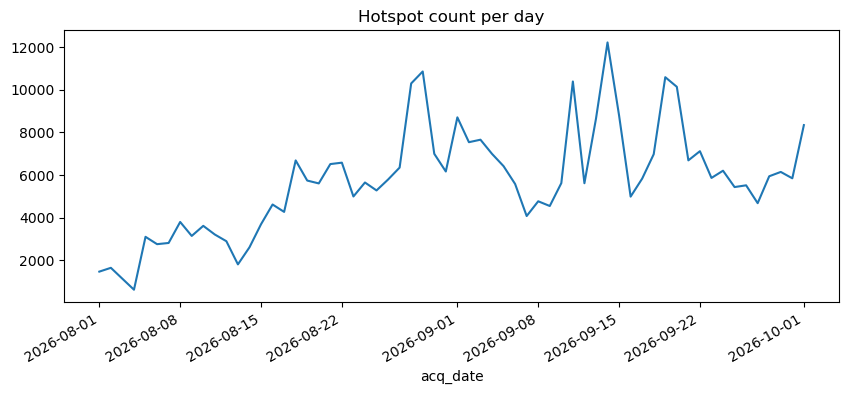

In [28]:
import matplotlib.pyplot as plt

harian = df.groupby("acq_date").size()
harian.plot(figsize=(10, 4), title="Hotspot count per day")
plt.show()

In [29]:
%pip install folium mapclassify

Note: you may need to restart the kernel to use updated packages.


<Axes: >

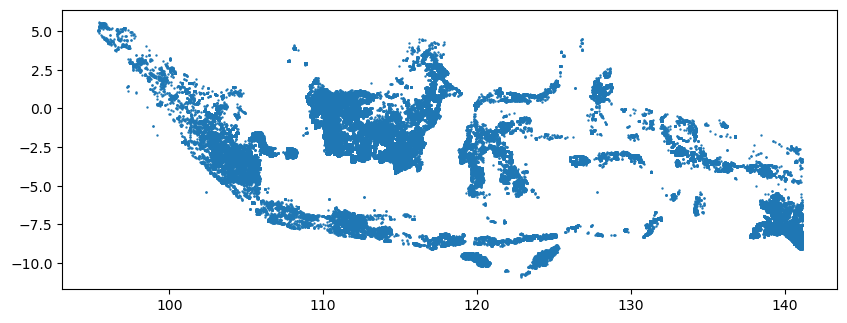

In [30]:
# Sample points to keep the interactive map lightweight
gdf.sample(min(5000, len(gdf))).explore(column="frp", cmap="YlOrRd", legend=True)

# Static map of all points (alternative)
gdf.plot(markersize=0.5, figsize=(10, 6))

NAME_1
Kalimantan Tengah      100452
Kalimantan Barat        62640
Papua                   40228
Sumatera Selatan        27828
Kalimantan Timur        19982
Kalimantan Selatan      16391
Maluku                  11642
Papua Barat              7444
Nusa Tenggara Timur      7117
Sulawesi Tengah          5653
dtype: int64


<Axes: >

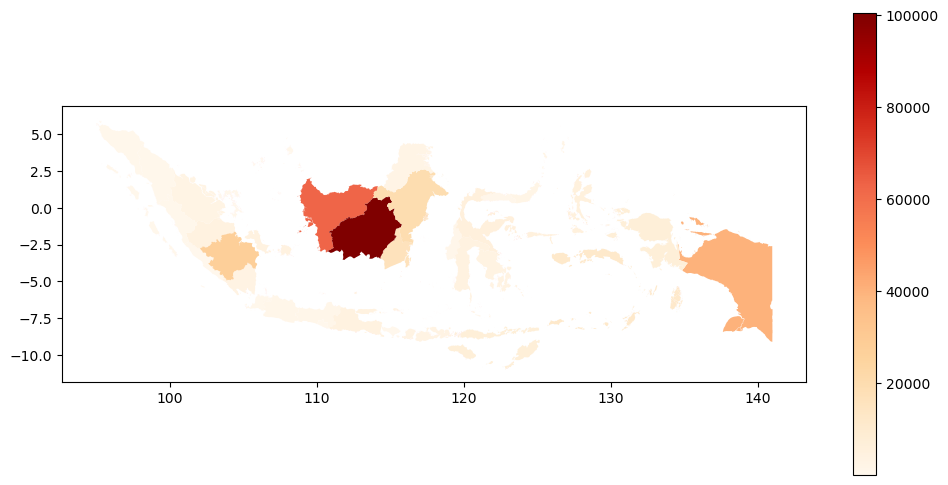

In [31]:
# Load province boundaries (GADM level 1)
prov = gpd.read_file(r"C:\Users\USER\OneDrive\Desktop\NASA\gadm41_IDN_1.shp")  # adjust file name

# Spatial join: assign each hotspot to the province it falls in
joined = gpd.sjoin(gdf, prov[["NAME_1", "geometry"]], predicate="within")

# Count hotspots per province
per_prov = joined.groupby("NAME_1").size().sort_values(ascending=False)
print(per_prov.head(10))

# Choropleth map of hotspot counts
prov["count"] = prov["NAME_1"].map(per_prov).fillna(0)
prov.plot(column="count", cmap="OrRd", legend=True, figsize=(12, 6))

In [32]:
import os

# Confirm the GADM files are in the folder
folder = r"C:\Users\USER\OneDrive\Desktop\NASA"
print([f for f in os.listdir(folder) if "gadm" in f.lower()])

# Load province boundaries (GADM level 1)
prov = gpd.read_file(os.path.join(folder, "gadm41_IDN_1.shp"))
print(prov.shape)            # expect around 38 rows (provinces)
print(prov.crs)              # should be EPSG:4326
print(prov["NAME_1"].head())

['gadm41_IDN_0.cpg', 'gadm41_IDN_0.dbf', 'gadm41_IDN_0.prj', 'gadm41_IDN_0.shp', 'gadm41_IDN_0.shx', 'gadm41_IDN_1.cpg', 'gadm41_IDN_1.dbf', 'gadm41_IDN_1.prj', 'gadm41_IDN_1.shp', 'gadm41_IDN_1.shx', 'gadm41_IDN_2.cpg', 'gadm41_IDN_2.dbf', 'gadm41_IDN_2.prj', 'gadm41_IDN_2.shp', 'gadm41_IDN_2.shx', 'gadm41_IDN_3.cpg', 'gadm41_IDN_3.dbf', 'gadm41_IDN_3.prj', 'gadm41_IDN_3.shp', 'gadm41_IDN_3.shx', 'gadm41_IDN_4.cpg', 'gadm41_IDN_4.dbf', 'gadm41_IDN_4.prj', 'gadm41_IDN_4.shp', 'gadm41_IDN_4.shx']
(34, 12)
EPSG:4326
0               Aceh
1               Bali
2    Bangka Belitung
3             Banten
4           Bengkulu
Name: NAME_1, dtype: object


In [33]:
# Make sure both layers use the same CRS
prov = prov.to_crs(gdf.crs)

# Join points to provinces (this can take a minute for large data)
joined = gpd.sjoin(gdf, prov[["NAME_1", "geometry"]], predicate="within", how="inner")
print(len(gdf), "hotspots ->", len(joined), "matched to a province")

353076 hotspots -> 349022 matched to a province


In [34]:
# Top provinces by hotspot count
per_prov = joined.groupby("NAME_1").size().sort_values(ascending=False)
print(per_prov.head(10))

# Share of total (%)
print((per_prov / per_prov.sum() * 100).round(1).head(10))

NAME_1
Kalimantan Tengah      100452
Kalimantan Barat        62640
Papua                   40228
Sumatera Selatan        27828
Kalimantan Timur        19982
Kalimantan Selatan      16391
Maluku                  11642
Papua Barat              7444
Nusa Tenggara Timur      7117
Sulawesi Tengah          5653
dtype: int64
NAME_1
Kalimantan Tengah      28.8
Kalimantan Barat       17.9
Papua                  11.5
Sumatera Selatan        8.0
Kalimantan Timur        5.7
Kalimantan Selatan      4.7
Maluku                  3.3
Papua Barat             2.1
Nusa Tenggara Timur     2.0
Sulawesi Tengah         1.6
dtype: float64


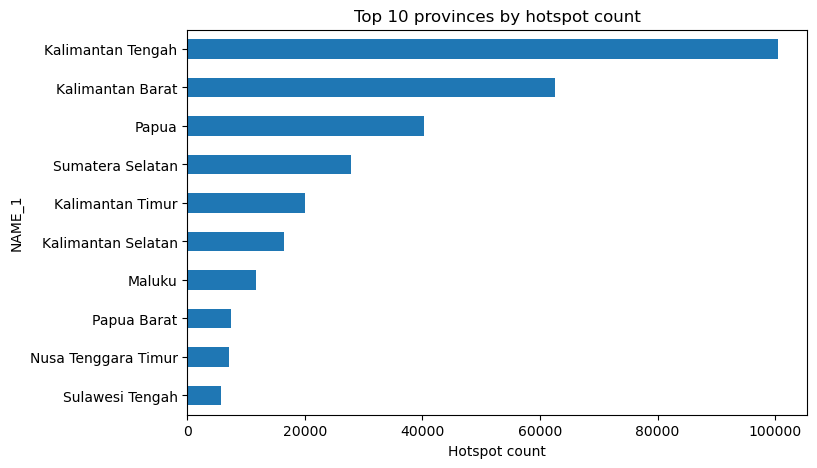

In [35]:
import matplotlib.pyplot as plt

# Bar chart: top 10 provinces
per_prov.head(10).sort_values().plot(kind="barh", figsize=(8, 5), title="Top 10 provinces by hotspot count")
plt.xlabel("Hotspot count")
plt.show()

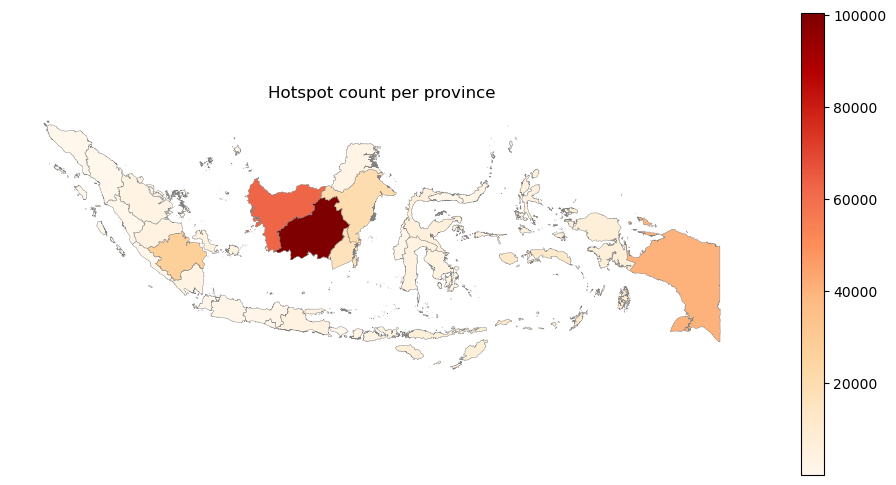

In [36]:
# Choropleth map: hotspot count per province
prov["count"] = prov["NAME_1"].map(per_prov).fillna(0)

fig, ax = plt.subplots(figsize=(12, 6))
prov.plot(column="count", cmap="OrRd", legend=True, edgecolor="grey", linewidth=0.3, ax=ax)
ax.set_title("Hotspot count per province")
ax.set_axis_off()
plt.show()

In [37]:
# Check the date range covered by the data
print(df["acq_date"].min(), "to", df["acq_date"].max())

2026-08-01 00:00:00 to 2026-10-01 00:00:00


In [38]:
# Normalize by province area (project to an equal-area CRS first)
prov_area = prov.to_crs("EPSG:6933")
prov["area_km2"] = prov_area.geometry.area / 1e6

prov["count"] = prov["NAME_1"].map(per_prov).fillna(0)
prov["per_1000km2"] = prov["count"] / prov["area_km2"] * 1000

print(prov.sort_values("per_1000km2", ascending=False)[["NAME_1", "count", "per_1000km2"]].head(10))

                 NAME_1   count  per_1000km2
13    Kalimantan Tengah  100452   653.510120
12   Kalimantan Selatan   16391   438.580109
11     Kalimantan Barat   62640   426.487203
31     Sumatera Selatan   27828   319.894468
2       Bangka Belitung    4646   277.236784
18               Maluku   11642   251.187289
20  Nusa Tenggara Barat    3441   174.932557
19         Maluku Utara    5266   167.125988
14     Kalimantan Timur   19982   158.774897
21  Nusa Tenggara Timur    7117   153.238781


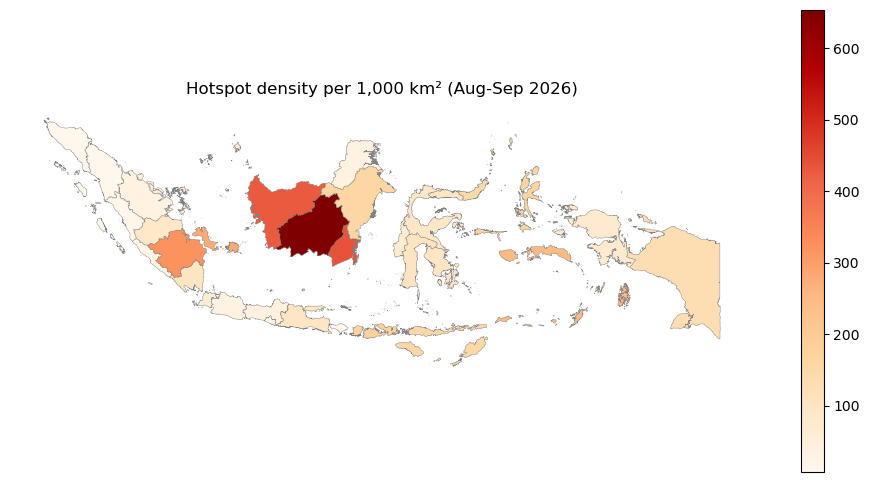

In [39]:
import matplotlib.pyplot as plt

# Choropleth of normalized hotspot density
fig, ax = plt.subplots(figsize=(12, 6))
prov.plot(column="per_1000km2", cmap="OrRd", legend=True,
          edgecolor="grey", linewidth=0.3, ax=ax)
ax.set_title("Hotspot density per 1,000 km² (Aug-Sep 2026)")
ax.set_axis_off()
plt.show()

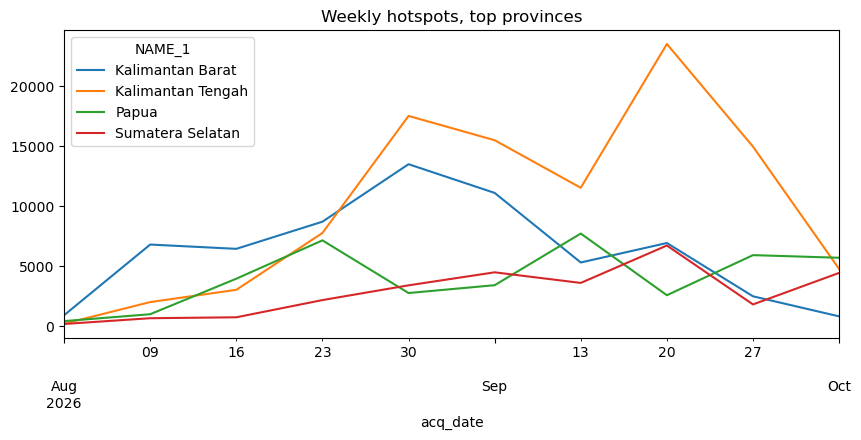

In [40]:
# Weekly trend for the top 4 provinces (shows how the season builds up)
top4 = per_prov.head(4).index
weekly = (joined[joined["NAME_1"].isin(top4)]
          .groupby([pd.Grouper(key="acq_date", freq="W"), "NAME_1"])
          .size().unstack())
weekly.plot(figsize=(10, 4), title="Weekly hotspots, top provinces")
plt.show()

In [41]:
# Fire radiative power (FRP) per province: which provinces have the most intense fires?
frp_prov = (joined.groupby("NAME_1")["frp"]
            .agg(["count", "mean", "median", "max"])
            .sort_values("count", ascending=False)
            .head(10))
print(frp_prov.round(1))

                      count  mean  median    max
NAME_1                                          
Kalimantan Tengah    100452   7.1     3.6  402.3
Kalimantan Barat      62640   8.7     4.8  392.0
Papua                 40228   8.2     5.0  319.8
Sumatera Selatan      27828   7.5     4.2  346.6
Kalimantan Timur      19982   6.5     4.0  249.9
Kalimantan Selatan    16391   7.1     4.5  214.8
Maluku                11642   5.3     3.1  185.9
Papua Barat            7444   6.6     2.8  235.2
Nusa Tenggara Timur    7117   6.7     4.7  152.3
Sulawesi Tengah        5653   6.4     3.8  191.4


In [42]:
from sklearn.cluster import DBSCAN
import numpy as np

# Cluster hotspots on a Kalimantan subset (eps ~ 5 km in radians)
sub = df[(df.longitude.between(108, 119)) & (df.latitude.between(-4.5, 2))]
coords = np.radians(sub[["latitude", "longitude"]].values)
db = DBSCAN(eps=5/6371, min_samples=30, metric="haversine").fit(coords)
sub = sub.assign(cluster=db.labels_)
print(sub["cluster"].value_counts().head(10))   # -1 = noise

cluster
 12    22191
 11    15631
 0     14545
-1     11969
 2     11130
 94    10878
 20    10769
 1      8928
 10     7281
 54     4700
Name: count, dtype: int64


In [43]:
%pip install pydeck

Note: you may need to restart the kernel to use updated packages.


In [44]:
import pydeck as pdk

# Keep only the columns needed so the map stays light
pts = df[["longitude", "latitude"]].copy()

layer = pdk.Layer(
    "HexagonLayer",
    data=pts,
    get_position="[longitude, latitude]",
    radius=15000,              # hexagon radius in meters
    elevation_scale=10,        # increase for taller bars, decrease for shorter
    extruded=True,             # makes the hexagons 3D
    coverage=0.9,
    pickable=True,
    auto_highlight=True,
)

view = pdk.ViewState(longitude=118, latitude=-2, zoom=4, pitch=50, bearing=0)

deck = pdk.Deck(
    layers=[layer],
    initial_view_state=view,
    tooltip={"text": "Hotspots in this cell: {elevationValue}"},
)

# Save to a file only, do not embed the map inside the notebook output
deck.to_html("hotspots_3d.html", open_browser=False, notebook_display=False)

In [45]:
import os
# Show the folder where hotspots_3d.html is saved
print(os.getcwd())

C:\Users\USER
